# Segmentación de jugadores con Modelos de Mezcla Gaussiana (GMM)

## Objetivo

Agrupar a los jugadores de **tres escenarios** (economía del juego, detección de hackers y estilos de batalla) con un **Modelo de Mezcla Gaussiana**. A diferencia de k-means, el GMM no solo asigna un grupo a cada jugador, también estima **con qué probabilidad** pertenece a cada uno.

## Idea del modelo

El GMM supone que los datos vienen de $K$ grupos ocultos y que cada grupo forma una **campana gaussiana** (en 2D, una elipse). La densidad total es una suma ponderada de esas gaussianas:

$$
p(\mathbf{x}) = \sum_{k=1}^{K} \pi_k \, \mathcal{N}(\mathbf{x} \mid \boldsymbol{\mu}_k, \boldsymbol{\Sigma}_k)
$$

- $\pi_k$: peso del grupo (qué proporción de jugadores contiene).
- $\boldsymbol{\mu}_k$: centro del grupo.
- $\boldsymbol{\Sigma}_k$: covarianza, que define la forma, el tamaño y la inclinación de la elipse.

## Cómo aprende: algoritmo EM

Como no se conoce el grupo real de cada jugador, el modelo repite dos pasos hasta converger:

1. **Paso E:** calcula la probabilidad de que cada jugador pertenezca a cada grupo, usando los parámetros actuales.
2. **Paso M:** recalcula $\pi_k$, $\boldsymbol{\mu}_k$ y $\boldsymbol{\Sigma}_k$ como promedios ponderados por esas probabilidades.

Cada iteración mejora el ajuste a los datos. Como puede quedar en un máximo local, se ejecuta varias veces y se conserva el mejor resultado.

## Etiquetas

La etiqueta final de cada jugador es el grupo con **mayor probabilidad**. Esto es lo que devuelve **fit_predict** y lo que se grafica.

## Configuración
1. n_components = 3, representa la cantidad grupos.
2. covariance_type = full, representa los elipses de cada grupo de cualquier forma e inclinación.
3. n_init = 10, repite el ajuste 10 veces y se conserva el mejor.
4. random_state = 42, representa la semilla fija para los resultados reproducibles.

Antes de ajustar, las variables se **estandarizan** para que ninguna domine por tener una escala mayor (por ejemplo, metros frente a cajas de loot).

In [1]:
from sklearn.preprocessing import StandardScaler
from sklearn.mixture import GaussianMixture
import pandas as pd
import numpy as np 

df = pd.read_csv('comportamiento_jugadores.csv')

display(df.head(5))

display(df)

,Metrica_X,Metrica_Y,Escenario,Descripcion_Ejes
0,44.125085,74.436148,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
1,19.905609,115.313604,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
2,55.833550,119.616643,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
3,10.243052,129.259511,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
4,5.413660,259.896958,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD


,Metrica_X,Metrica_Y,Escenario,Descripcion_Ejes
0,44.125085,74.436148,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
1,19.905609,115.313604,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
2,55.833550,119.616643,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
3,10.243052,129.259511,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
4,5.413660,259.896958,1_Economia_Juego,X: Horas_Semana | Y: Gasto_USD
...,...,...,...,...
1795,2270.067519,72.707213,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas
1796,1003.790472,64.590489,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas
1797,3309.609429,23.893436,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas
1798,1650.694480,44.669431,3_Estilos_Batalla,X: Distancia_Metros | Y: Cajas_Loot_Abiertas


In [2]:
escenarios = df['Escenario'].unique()

datos_escenario = {}
matrices_X={}

for escenario in escenarios:
    df_escenario = df[df['Escenario'] == escenario].copy()
    
    X = df_escenario[['Metrica_X', 'Metrica_Y']]
    
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X)
    
    datos_escenario[escenario] = df_escenario
    matrices_X[escenario] = X_scaled
    
    print('Ejes: ', df_escenario['Descripcion_Ejes'].iloc[0])
    print("Matriz: ", X_scaled.shape)
    print("Media: ", np.mean(X_scaled, axis=0))
    print("Media antes de escalar: ", np.mean(X, axis=0))
    print("Desviación estándar: ", np.std(X_scaled, axis=0))


Ejes:  X: Horas_Semana | Y: Gasto_USD
Matriz:  (600, 2)
Media:  [ 7.10542736e-17 -1.06581410e-16]
Media antes de escalar:  Metrica_X     24.497549
Metrica_Y    165.169711
dtype: float64
Desviación estándar:  [1. 1.]
Ejes:  X: KDA_Ratio | Y: Porcentaje_Headshots
Matriz:  (600, 2)
Media:  [-2.08721929e-16  6.51330841e-16]
Media antes de escalar:  Metrica_X     7.007907
Metrica_Y    55.132256
dtype: float64
Desviación estándar:  [1. 1.]
Ejes:  X: Distancia_Metros | Y: Cajas_Loot_Abiertas
Matriz:  (600, 2)
Media:  [-5.32907052e-17 -2.25005200e-16]
Media antes de escalar:  Metrica_X    2002.541617
Metrica_Y      40.170044
dtype: float64
Desviación estándar:  [1. 1.]


In [3]:
X_economia = matrices_X['1_Economia_Juego']
X_hackers = matrices_X['2_Deteccion_Hackers']
X_batalla = matrices_X['3_Estilos_Batalla']

print("Economía:", X_economia.shape)
print("Hackers:", X_hackers.shape)
print("Batalla:", X_batalla.shape)

Economía: (600, 2)
Hackers: (600, 2)
Batalla: (600, 2)


In [4]:
gmm = GaussianMixture(n_components = 3, covariance_type = 'full', n_init = 10, random_state = 42)

etiquetas = gmm.fit_predict(matrices_X[escenarios[0]])

display(etiquetas)

array([1, 2, 1, 2, 0, 0, 1, 0, 1, 1, 0, 0, 2, 2, 0, 0, 1, 2, 0, 1, 0, 2,
       1, 0, 2, 0, 1, 1, 1, 1, 1, 1, 0, 0, 0, 2, 0, 0, 2, 0, 0, 0, 1, 1,
       1, 2, 0, 2, 0, 1, 1, 2, 2, 0, 1, 0, 1, 0, 0, 1, 0, 1, 1, 2, 0, 1,
       0, 2, 2, 2, 0, 1, 1, 1, 2, 2, 1, 2, 2, 2, 1, 0, 1, 1, 2, 2, 1, 2,
       2, 2, 0, 2, 2, 0, 0, 1, 1, 2, 2, 0, 1, 0, 0, 2, 0, 2, 1, 0, 1, 1,
       2, 2, 0, 0, 2, 2, 1, 2, 0, 2, 0, 0, 0, 2, 2, 0, 1, 2, 1, 1, 0, 2,
       0, 1, 0, 1, 2, 0, 1, 1, 0, 2, 0, 0, 0, 2, 2, 2, 2, 0, 1, 0, 1, 2,
       2, 2, 1, 2, 2, 0, 0, 0, 0, 2, 0, 1, 0, 2, 0, 0, 0, 2, 2, 0, 1, 2,
       2, 1, 1, 2, 0, 0, 2, 2, 0, 1, 0, 2, 1, 1, 2, 2, 0, 0, 2, 0, 1, 1,
       1, 1, 2, 1, 0, 0, 2, 2, 2, 0, 2, 1, 1, 0, 1, 1, 2, 2, 0, 1, 0, 2,
       0, 1, 1, 0, 0, 2, 2, 2, 1, 0, 0, 2, 0, 0, 1, 1, 1, 2, 1, 0, 0, 1,
       0, 1, 0, 2, 0, 2, 2, 0, 1, 1, 0, 2, 0, 2, 1, 0, 1, 1, 0, 2, 1, 2,
       1, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 2, 0, 1, 1, 1, 0, 1, 0, 0, 1, 1,
       0, 1, 2, 1, 1, 1, 1, 1, 1, 2, 1, 0, 0, 1, 2,

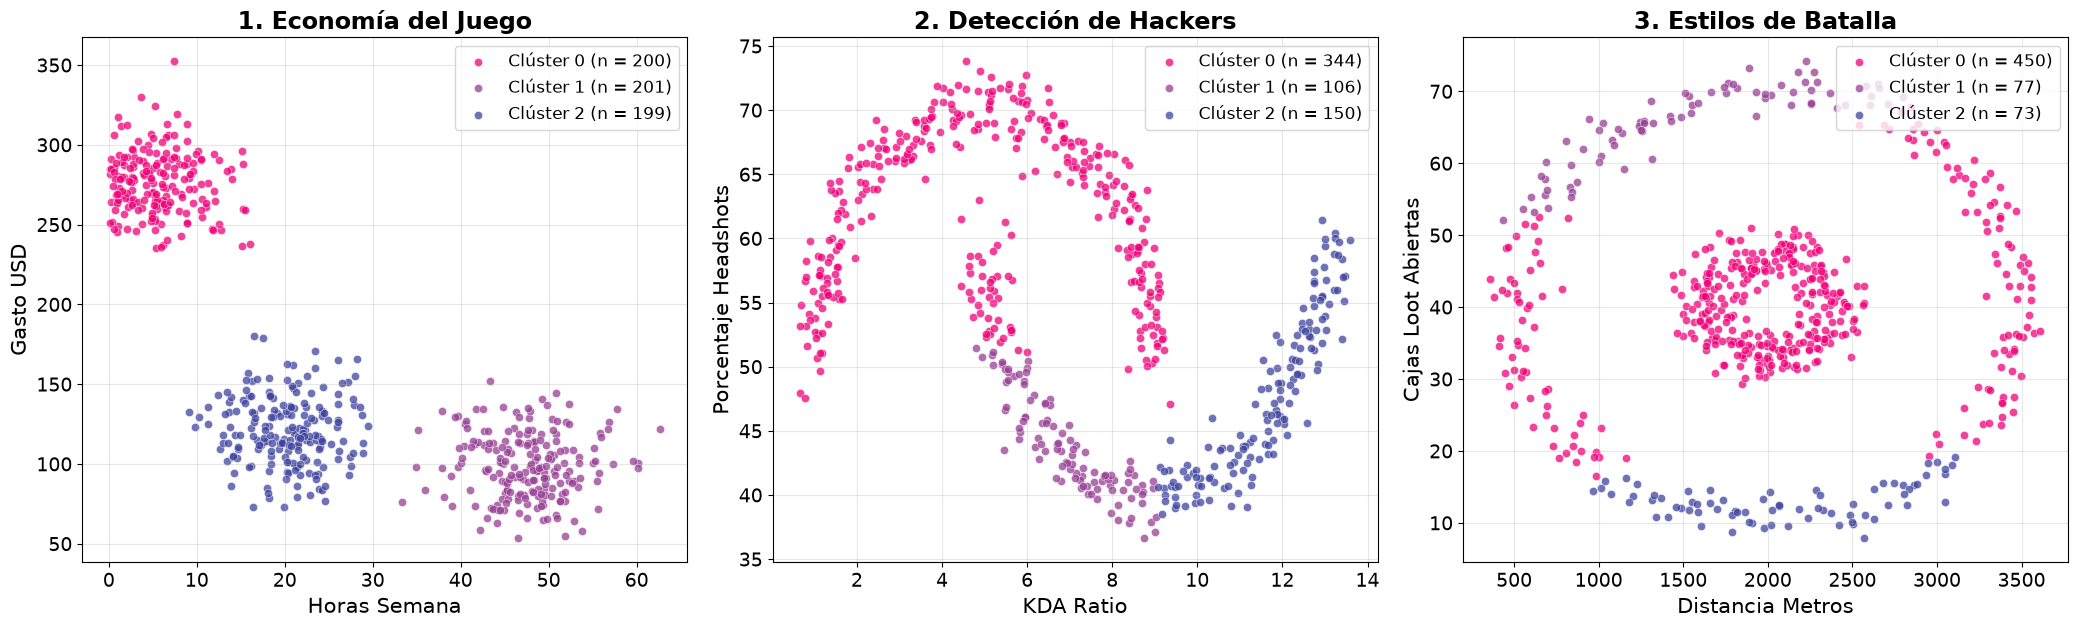

In [5]:
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 14, 'axes.titlesize': 17, 'axes.labelsize': 15})
colores = ['#f00078', '#973e95', '#3e439f']

# Etiquetas de cada escenario
def ajustar_etiquetas(X):
    gmm = GaussianMixture(n_components=3, covariance_type='full', n_init=10, random_state=42)
    return gmm.fit_predict(X)

labels_economia = ajustar_etiquetas(X_economia)
labels_hackers  = ajustar_etiquetas(X_hackers)
labels_estilos  = ajustar_etiquetas(X_batalla)

paneles = [
    ('1_Economia_Juego',    labels_economia, "1. Economía del Juego"),
    ('2_Deteccion_Hackers', labels_hackers,  "2. Detección de Hackers"),
    ('3_Estilos_Batalla',   labels_estilos,  "3. Estilos de Batalla"),
]

fig, axes = plt.subplots(1, 3, figsize=(21, 6.5))

for ax, (clave, labels, titulo) in zip(axes, paneles):
    df_e = datos_escenario[clave]                      # datos en unidades originales
    x = df_e['Metrica_X'].to_numpy()
    y = df_e['Metrica_Y'].to_numpy()

    # 'X: Horas_Semana | Y: Gasto_USD' -> 'Horas Semana', 'Gasto USD'
    nombre_x, nombre_y = [p.split(':', 1)[1].strip().replace('_', ' ')
                          for p in df_e['Descripcion_Ejes'].iloc[0].split('|')]

    for k in range(3):
        m = labels == k
        ax.scatter(x[m], y[m], color=colores[k], s=35, alpha=0.75,
                   edgecolor='white', linewidth=0.4,
                   label=f"Clúster {k} (n = {m.sum()})")

    ax.set_title(titulo, fontweight='bold')
    ax.set_xlabel(nombre_x)
    ax.set_ylabel(nombre_y)
    ax.grid(True, alpha=0.3)
    ax.legend(loc='best', fontsize=12)

plt.tight_layout()
plt.show()